<a href="https://colab.research.google.com/github/syifaST/simuteh--2330511062-/blob/main/notebook/B5_praproses.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import os, sys
REPO = "https://github.com/syifaST/simuteh--2330511062-.git"

if not os.path.exists("/content/simuteh"):
    !git clone {REPO} /content/simuteh
os.chdir("/content/simuteh")

for f in ["notebook", "hasil", "laporan"]:
    os.makedirs(f, exist_ok=True)

# buat ulang dataset kalau ada folder atau label.csv yang kurang
perlu = ["citra", "bersih", "mask_daun", "mask_bercak"]
if (not all(os.path.exists(f"data/sintetis/{d}") for d in perlu)
        or not os.path.exists("data/sintetis/label.csv")):
    !python src/buat_dataset_sintetis.py

os.chdir("/content/simuteh/notebook")
sys.path.append("../src")

print("Folder kerja:", os.getcwd())
print("Jumlah citra:", len(os.listdir("../data/sintetis/citra")))
print("Jumlah bersih:", len(os.listdir("../data/sintetis/bersih")))
print("Isi src:", os.listdir("../src"))

Folder kerja: /content/simuteh/notebook
Jumlah citra: 61
Jumlah bersih: 61
Isi src: ['utils_cv.py', 'praproses.py', 'buat_dataset_sintetis.py', '__pycache__']


In [10]:
import json, cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from utils_cv import baca, kontras_bercak
from praproses import praproses, simpan_param

KANAL = 2   # kanal R (indeks BGR), kanal terbaik Bagian 2
urut = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
label = pd.read_csv("../data/sintetis/label.csv")
berbercak = label[label.kelas != "sehat"]   # 40 citra
sehat = label[label.kelas == "sehat"]       # 20 citra

kandidat = {
    "A_median3": {"gamma": 1.0, "clahe_clip": 2.0, "clahe_tile": 8,
                  "penapis": "median", "kernel": 3, "sigma": 1.0, "tajam_k": 0.0},
    "B_gauss5":  {"gamma": 1.0, "clahe_clip": 2.0, "clahe_tile": 8,
                  "penapis": "gaussian", "kernel": 5, "sigma": 1.0, "tajam_k": 0.0},
}

def muat(d):
    img = baca(f"../data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    return img, md, mb

def evaluasi(p):
    baris = []
    for _, d in berbercak.iterrows():
        img, md, mb = muat(d)
        out = praproses(img, p)
        baris.append([d.kondisi_cahaya,
                      kontras_bercak(img[:, :, KANAL], md, mb),
                      kontras_bercak(out[:, :, KANAL], md, mb)])
    return pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"])

ringkas = {}
for nm, p in kandidat.items():
    ringkas[nm] = evaluasi(p).groupby("kondisi").mean().loc[urut]
    print(f"{nm}: rerata KB sesudah (5 kondisi) = {ringkas[nm].KB_sesudah.mean():.2f}")

terpilih = "B_gauss5"   # pilih "A_median3" atau "B_gauss5" setelah membaca perbandingan di atas
param = kandidat[terpilih]
print("\nParameter terpilih:", terpilih)
simpan_param(param, "../hasil/param_praproses.json")

perbandingan = pd.DataFrame({n: r.KB_sesudah for n, r in ringkas.items()}).round(2)
perbandingan.insert(0, "sebelum", ringkas[terpilih].KB_sebelum.round(2))
print("\nPerbandingan kandidat (KB):")
print(perbandingan)

hasil = ringkas[terpilih].round(2).copy()
hasil["perubahan_%"] = ((hasil.KB_sesudah / hasil.KB_sebelum - 1) * 100).round(1)
print("\nTabel 12 (parameter terpilih):")
print(hasil)
hasil.to_csv("../hasil/b5_tabel12.csv")
perbandingan.to_csv("../hasil/b5_perbandingan_kandidat.csv")

A_median3: rerata KB sesudah (5 kondisi) = 9.60
B_gauss5: rerata KB sesudah (5 kondisi) = 9.67

Parameter terpilih: B_gauss5

Perbandingan kandidat (KB):
                sebelum  A_median3  B_gauss5
kondisi                                     
normal             9.02      11.06     11.07
gelap             10.40      17.48     16.58
terang             6.64       5.84      6.17
kontras_rendah     3.91       4.99      5.55
bayangan           5.09       8.64      8.99

Tabel 12 (parameter terpilih):
                KB_sebelum  KB_sesudah  perubahan_%
kondisi                                            
normal                9.02       11.07         22.7
gelap                10.40       16.58         59.4
terang                6.64        6.17         -7.1
kontras_rendah        3.91        5.55         41.9
bayangan              5.09        8.99         76.6


                std_sebelum  std_sesudah
kondisi                                 
normal                10.62         9.76
gelap                  8.82         6.44
terang                10.67        11.26
kontras_rendah        10.08         9.09
bayangan              13.99        10.20


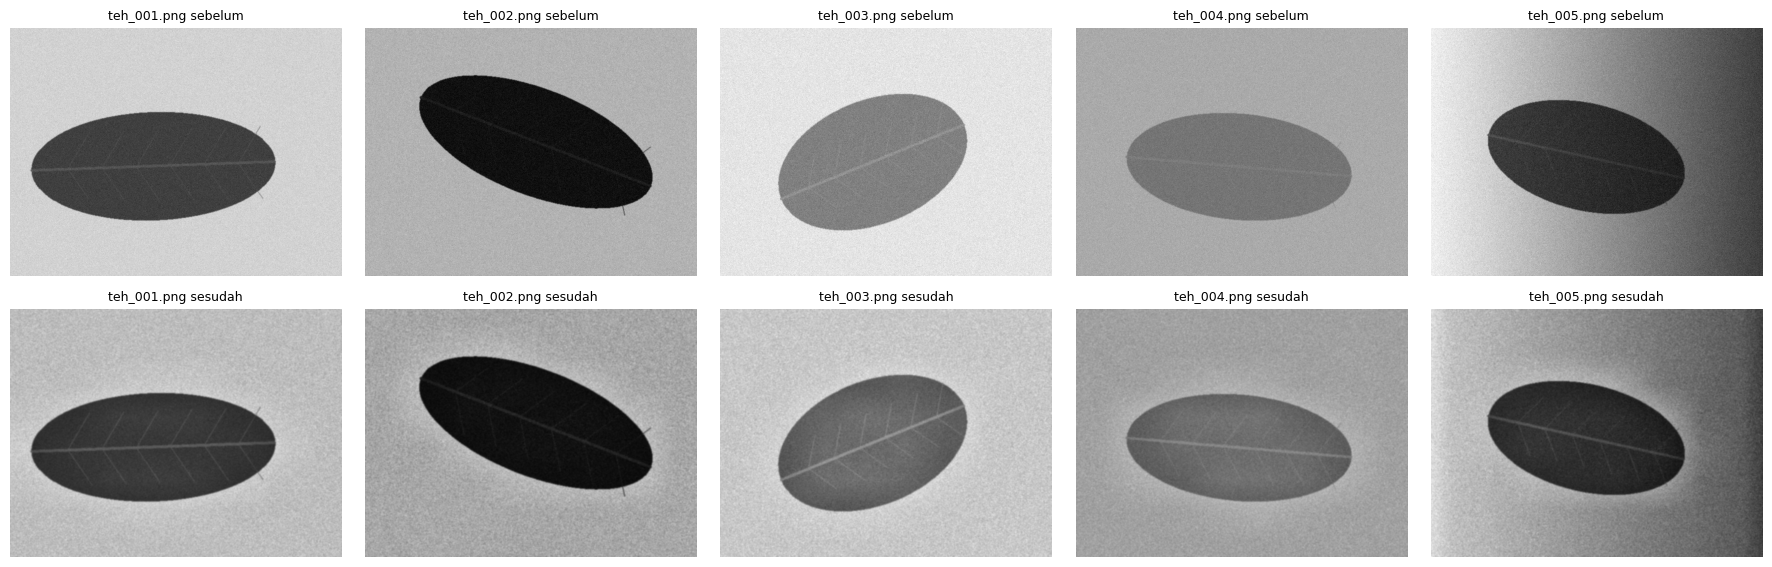

In [11]:
baris = []
for _, d in sehat.iterrows():
    img, md, mb = muat(d)
    out = praproses(img, param)
    baris.append([d.kondisi_cahaya,
                  img[:, :, KANAL][md > 0].std(),
                  out[:, :, KANAL][md > 0].std()])
uji = pd.DataFrame(baris, columns=["kondisi", "std_sebelum", "std_sesudah"])
rata_uji = uji.groupby("kondisi").mean().loc[urut].round(2)
print(rata_uji)
rata_uji.to_csv("../hasil/b5_uji_sehat.csv")

daftar = ["teh_001.png", "teh_002.png", "teh_003.png", "teh_004.png", "teh_005.png"]
fig, ax = plt.subplots(2, 5, figsize=(18, 6))
for j, nm in enumerate(daftar):
    img = baca(f"../data/sintetis/citra/{nm}"); out = praproses(img, param)
    for i, im in enumerate([img, out]):
        ax[i, j].imshow(im[:, :, KANAL], cmap="gray", vmin=0, vmax=255)
        ax[i, j].set_title(f"{nm} {'sebelum' if i == 0 else 'sesudah'}", fontsize=9)
        ax[i, j].axis("off")
plt.tight_layout(); plt.savefig("../hasil/b5_uji_sehat.png"); plt.show()

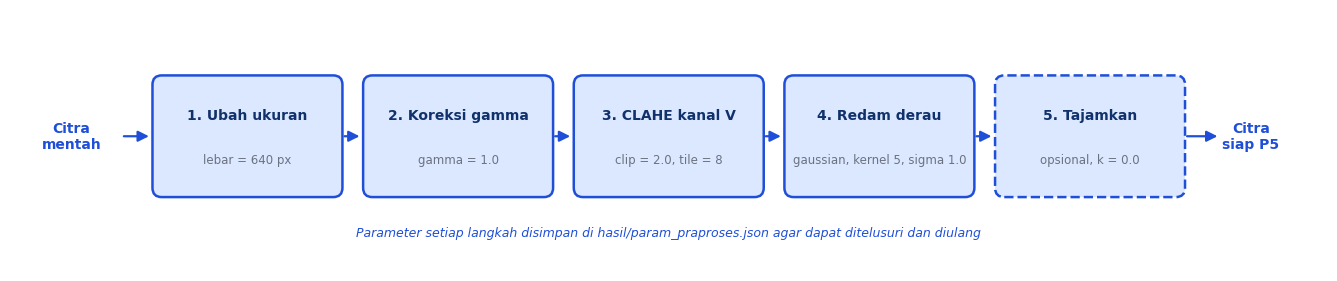

In [12]:
from matplotlib.patches import FancyBboxPatch

p = json.load(open("../hasil/param_praproses.json"))
sub4 = f"{p['penapis']}, kernel {p['kernel']}"
if p["penapis"] == "gaussian":
    sub4 += f", sigma {p['sigma']}"

kotak = [
    ("1. Ubah ukuran", f"lebar = {p['lebar']} px", False),
    ("2. Koreksi gamma", f"gamma = {p['gamma']}", False),
    ("3. CLAHE kanal V", f"clip = {p['clahe_clip']}, tile = {p['clahe_tile']}", False),
    ("4. Redam derau", sub4, False),
    ("5. Tajamkan", f"opsional, k = {p['tajam_k']}", True),
]

fig, ax = plt.subplots(figsize=(17, 3.4))
ax.set_xlim(0, 17.2); ax.set_ylim(0, 3.4); ax.axis("off")
w, h, y = 2.4, 1.5, 1.0
xs = [1.9 + i * 2.75 for i in range(5)]

def panah(x1, x2):
    ax.annotate("", xy=(x2, y + h / 2), xytext=(x1, y + h / 2),
                arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#1f4fd8"))

ax.text(0.8, y + h / 2, "Citra\nmentah", ha="center", va="center",
        fontsize=10, fontweight="bold", color="#1f4fd8")
panah(1.45, xs[0] - 0.05)
for i, (x, (judul, isi, putus)) in enumerate(zip(xs, kotak)):
    ax.add_patch(FancyBboxPatch((x, y), w, h,
                 boxstyle="round,pad=0.04,rounding_size=0.12",
                 fc="#dbe8ff", ec="#1f4fd8", lw=1.8,
                 ls="--" if putus else "-"))
    ax.text(x + w / 2, y + h * 0.68, judul, ha="center", va="center",
            fontsize=10, fontweight="bold", color="#10316b")
    ax.text(x + w / 2, y + h * 0.30, isi, ha="center", va="center",
            fontsize=8.5, color="#6b7280")
    if i < 4:
        panah(x + w + 0.03, xs[i + 1] - 0.05)
panah(xs[4] + w + 0.03, xs[4] + w + 0.5)
ax.text(16.2, y + h / 2, "Citra\nsiap P5", ha="center", va="center",
        fontsize=10, fontweight="bold", color="#1f4fd8")
ax.text(8.6, 0.45, "Parameter setiap langkah disimpan di hasil/param_praproses.json "
        "agar dapat ditelusuri dan diulang",
        ha="center", fontsize=9, style="italic", color="#1f4fd8")

plt.savefig("../hasil/b5_diagram_praproses.png", dpi=150, bbox_inches="tight")
plt.show()

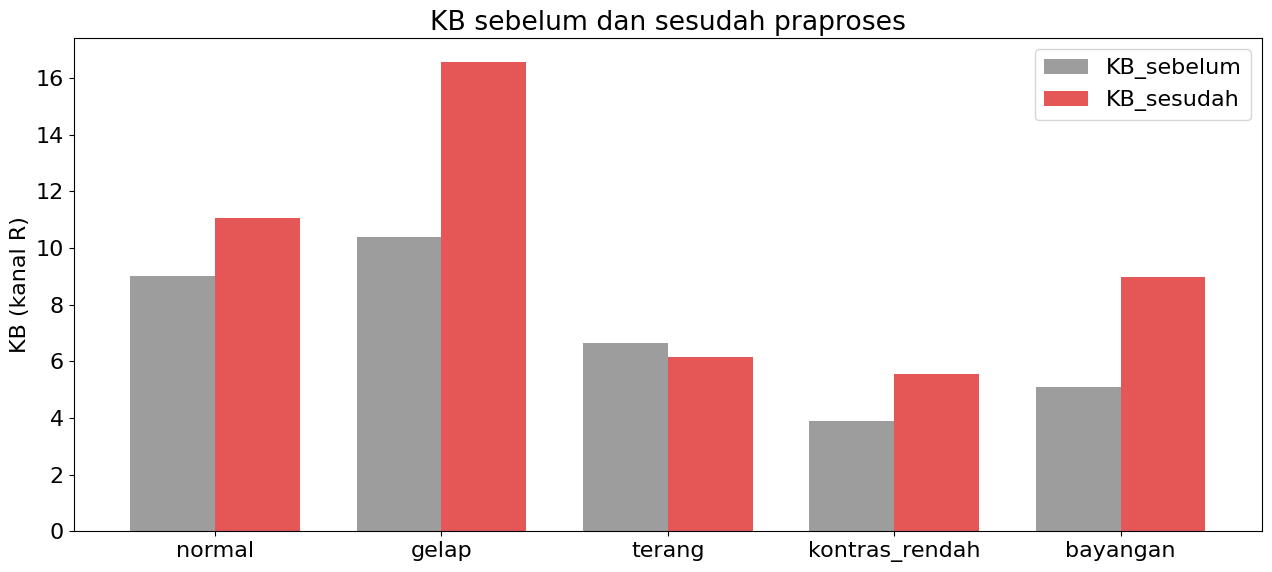

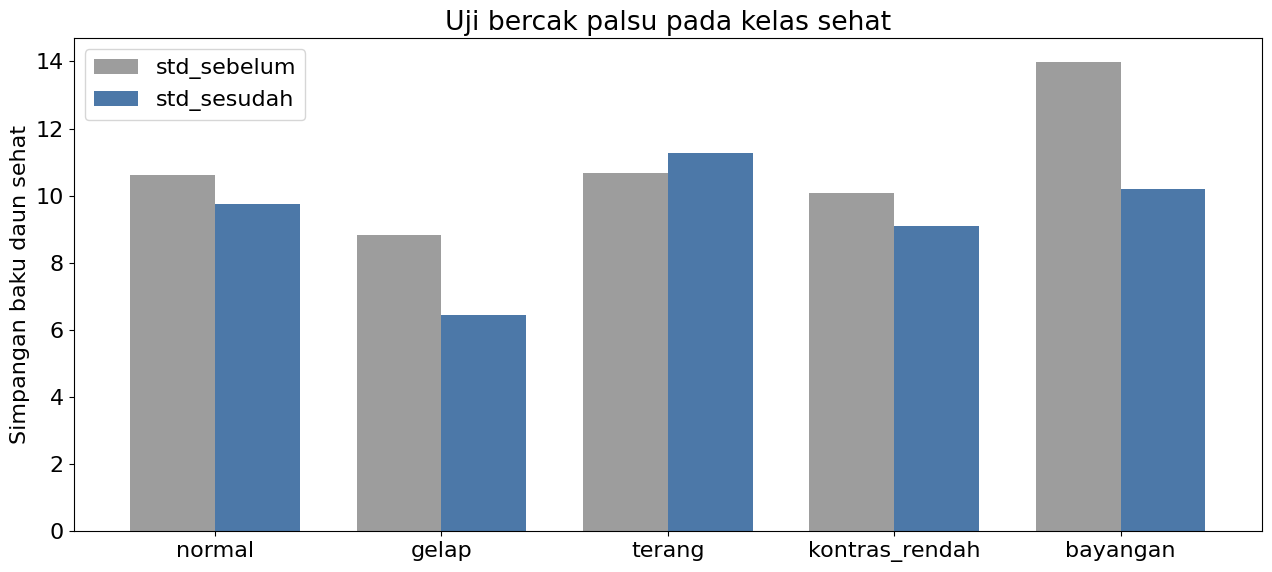

In [13]:
plt.rcParams.update({"font.size": 16})

ax = hasil.loc[urut, ["KB_sebelum", "KB_sesudah"]].plot(
    kind="bar", figsize=(13, 6), color=["#9d9d9d", "#e45756"], width=0.75)
ax.set_ylabel("KB (kanal R)"); ax.set_xlabel("")
ax.set_title("KB sebelum dan sesudah praproses")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("../hasil/b5_grafik_kb_praproses.png", dpi=200); plt.show()

ax = rata_uji.loc[urut].plot(kind="bar", figsize=(13, 6),
                             color=["#9d9d9d", "#4c78a8"], width=0.75)
ax.set_ylabel("Simpangan baku daun sehat"); ax.set_xlabel("")
ax.set_title("Uji bercak palsu pada kelas sehat")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("../hasil/b5_grafik_uji_sehat.png", dpi=200); plt.show()
plt.rcParams.update(plt.rcParamsDefault)

In [14]:
def param_adaptif(img, dasar):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    m, s = g.mean(), g.std()
    gamma = 1.0
    if s < 50:
        if m <= 130: gamma = 0.5     # gelap
        elif m >= 195: gamma = 1.8   # terang
    return {**dasar, "gamma": gamma}

baris = []
for _, d in berbercak.iterrows():
    img, md, mb = muat(d)
    tetap = praproses(img, param)
    adapt = praproses(img, param_adaptif(img, param))
    baris.append([d.kondisi_cahaya,
                  kontras_bercak(img[:, :, KANAL], md, mb),
                  kontras_bercak(tetap[:, :, KANAL], md, mb),
                  kontras_bercak(adapt[:, :, KANAL], md, mb)])
adaptif = (pd.DataFrame(baris, columns=["kondisi", "sebelum", "tetap", "adaptif"])
           .groupby("kondisi").mean().loc[urut].round(2))
print(adaptif)
adaptif.to_csv("../hasil/b5_adaptif.csv")

                sebelum  tetap  adaptif
kondisi                                
normal             9.02  11.07    11.07
gelap             10.40  16.58    11.63
terang             6.64   6.17     9.33
kontras_rendah     3.91   5.55     5.55
bayangan           5.09   8.99     8.60
